In [17]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the existing TF-IDF vectorizer and processed job dataset
job_tfidf = joblib.load("../models/job_tfidf_vectorizer.pkl")
jobs = pd.read_csv("../data/processed/processed_jobs.csv")

print("Jobs dataset shape:", jobs.shape)
print("\nAvailable columns:")
print(jobs.columns.tolist())

jobs.head()

Jobs dataset shape: (50000, 9)

Available columns:
['Job Title', 'Company', 'Location', 'Experience Level', 'Salary', 'Industry', 'Required Skills', 'Job_Text', 'Cluster']


,Job Title,Company,Location,Experience Level,Salary,Industry,Required Skills,Job_Text,Cluster
0,Early years teacher,Richardson Ltd,Sydney,Senior Level,87000.0,Healthcare,Pharmaceuticals,Early years teacher Healthcare Pharmaceuticals,4
1,Counselling psychologist,"Ramos, Santiago and Stewart",San Francisco,Mid Level,50000.0,Marketing,"Google Ads, SEO, Content Writing","Counselling psychologist Marketing Google Ads,...",5
2,Radio broadcast assistant,Franco Group,New York,Mid Level,77000.0,Healthcare,"Patient Care, Nursing, Medical Research, Pharm...",Radio broadcast assistant Healthcare Patient C...,4
3,"Designer, exhibition/display",Collins Inc,Berlin,Senior Level,90000.0,Software,Machine Learning,"Designer, exhibition/display Software Machine ...",0
4,"Psychotherapist, dance movement",Barker Group,Sydney,Entry Level,112000.0,Healthcare,"Nursing, Medical Research, Pharmaceuticals","Psychotherapist, dance movement Healthcare Nur...",4


In [2]:
# Check the existing job data and clustering
print("Total jobs:", len(jobs))
print("Number of clusters:", jobs["Cluster"].nunique())

print("\nJobs per cluster:")
print(jobs["Cluster"].value_counts().sort_index())

print("\nMissing values:")
print(jobs[["Job Title", "Required Skills", "Job_Text", "Cluster"]].isnull().sum())

Total jobs: 50000
Number of clusters: 7

Jobs per cluster:
Cluster
0    7300
1    7143
2    7169
3    7017
4    7104
5    7157
6    7110
Name: count, dtype: int64

Missing values:
Job Title          0
Required Skills    0
Job_Text           0
Cluster            0
dtype: int64


In [3]:
from sklearn.metrics.pairwise import cosine_similarity

def recommend_jobs(resume_text, top_n=5):
    # Convert resume text using the existing fitted vectorizer
    resume_vector = job_tfidf.transform([resume_text])

    # Calculate similarity with all job descriptions
    similarities = cosine_similarity(resume_vector, job_vectors).flatten()

    # Get the indices of the top matching jobs
    top_indices = similarities.argsort()[::-1][:top_n]

    results = jobs.iloc[top_indices][
        ["Job Title", "Company", "Location", "Required Skills", "Cluster"]
    ].copy()

    results["Match Score (%)"] = (
        similarities[top_indices] * 100
    ).round(2)

    return results.reset_index(drop=True)

In [6]:
sample_resume = """
Python, SQL, machine learning, data analysis,
pandas, scikit-learn, data visualization
"""

recommend_jobs(sample_resume, top_n=5)

,Job Title,Company,Location,Required Skills,Cluster,Match Score (%)
0,Data scientist,Navarro-Thompson,Sydney,"Python, SQL, React, Machine Learning",0,76.20
1,Data scientist,Ellis-Haynes,London,"Machine Learning, Java, SQL",0,73.50
2,Data scientist,Powell-Bryant,Toronto,"Machine Learning, SQL, Java, C++",0,73.50
3,Data scientist,Wells-Rogers,London,"Machine Learning, Java",0,70.64
4,Data scientist,Adams Ltd,Toronto,"AWS, Machine Learning",0,70.57


In [15]:
# Create job vectors using the already-loaded TF-IDF vectorizer
job_vectors = job_tfidf.transform(jobs["Job_Text"])

print("Job vectors shape:", job_vectors.shape)
print("Total job vectors:", job_vectors.shape[0])

Job vectors shape: (50000, 544)
Total job vectors: 50000


In [7]:
# Evaluate the top 5 recommendations
sample_recommendations = recommend_jobs(sample_resume, top_n=5)

print("Top 5 recommendation summary")
print("Unique job titles:", sample_recommendations["Job Title"].nunique())
print("Unique companies:", sample_recommendations["Company"].nunique())
print("Clusters represented:", sample_recommendations["Cluster"].nunique())
print("\nMatch score range:")
print(
    f'{sample_recommendations["Match Score (%)"].min():.2f}% - '
    f'{sample_recommendations["Match Score (%)"].max():.2f}%'
)

sample_recommendations

Top 5 recommendation summary
Unique job titles: 1
Unique companies: 5
Clusters represented: 1

Match score range:
70.57% - 76.20%


,Job Title,Company,Location,Required Skills,Cluster,Match Score (%)
0,Data scientist,Navarro-Thompson,Sydney,"Python, SQL, React, Machine Learning",0,76.20
1,Data scientist,Ellis-Haynes,London,"Machine Learning, Java, SQL",0,73.50
2,Data scientist,Powell-Bryant,Toronto,"Machine Learning, SQL, Java, C++",0,73.50
3,Data scientist,Wells-Rogers,London,"Machine Learning, Java",0,70.64
4,Data scientist,Adams Ltd,Toronto,"AWS, Machine Learning",0,70.57


In [8]:
# Inspect job titles and skills across all 7 clusters
cluster_summary = (
    jobs.groupby("Cluster")
    .agg(
        Total_Jobs=("Job Title", "size"),
        Unique_Job_Titles=("Job Title", "nunique"),
        Unique_Required_Skills=("Required Skills", "nunique")
    )
    .reset_index()
)

cluster_summary

,Cluster,Total_Jobs,Unique_Job_Titles,Unique_Required_Skills
0,0,7300,639,995
1,1,7143,639,64
2,2,7169,639,15
3,3,7017,639,206
4,4,7104,639,64
5,5,7157,639,205
6,6,7110,639,19


In [7]:

# Skill-overlap proxy evaluation (not true Precision@5)

sample_resume = """
Python, SQL, machine learning, data analysis,
pandas, scikit-learn, data visualization
"""

resume_skills = [
    "python", "sql", "machine learning", "data analysis",
    "pandas", "scikit-learn", "data visualization"
]

recommended = recommend_jobs(sample_resume, top_n=5)

def calculate_skill_overlap(required_skills, resume_skills):
    required = {
        skill.strip().lower()
        for skill in str(required_skills).split(",")
        if skill.strip()
    }

    resume = set(resume_skills)
    if not required:
        return 0.0

    return round(len(required & resume) / len(required) * 100, 2)

recommended["Skill Overlap (%)"] = recommended["Required Skills"].apply(
    lambda skills: calculate_skill_overlap(skills, resume_skills)
)

print("Average skill overlap (%):",
      round(recommended["Skill Overlap (%)"].mean(), 2))

recommended[
    ["Job Title", "Company", "Match Score (%)", "Required Skills", "Skill Overlap (%)"]
]


Average skill overlap (%): 58.33


,Job Title,Company,Match Score (%),Required Skills,Skill Overlap (%)
0,Data scientist,Navarro-Thompson,76.20,"Python, SQL, React, Machine Learning",75.00
1,Data scientist,Ellis-Haynes,73.50,"Machine Learning, Java, SQL",66.67
2,Data scientist,Powell-Bryant,73.50,"Machine Learning, SQL, Java, C++",50.00
3,Data scientist,Wells-Rogers,70.64,"Machine Learning, Java",50.00
4,Data scientist,Adams Ltd,70.57,"AWS, Machine Learning",50.00


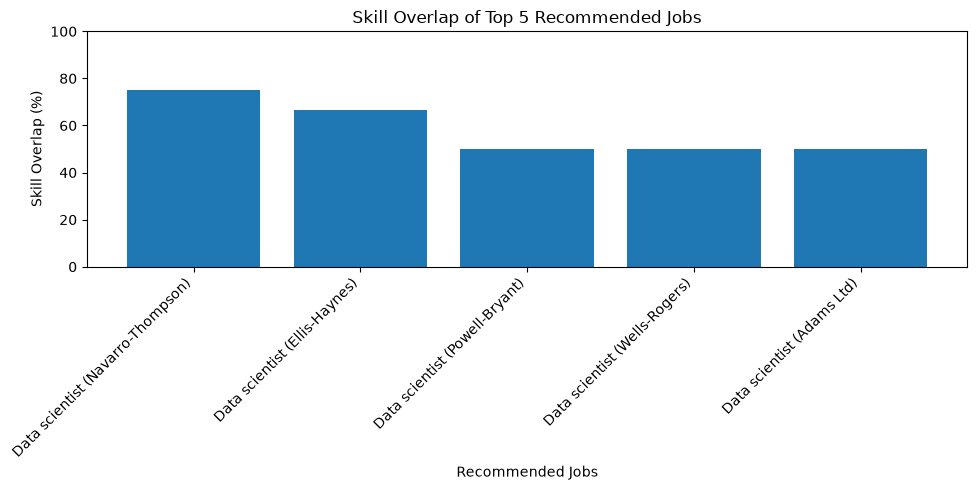

In [8]:
# Visualize recommendation evaluation results

plt.figure(figsize=(10, 5))

plt.bar(
    recommended["Job Title"] + " (" + recommended["Company"] + ")",
    recommended["Skill Overlap (%)"]
)

plt.title("Skill Overlap of Top 5 Recommended Jobs")
plt.xlabel("Recommended Jobs")
plt.ylabel("Skill Overlap (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [9]:
# Save recommendation evaluation results

output_columns = [
    "Job Title",
    "Company",
    "Match Score (%)",
    "Required Skills",
    "Skill Overlap (%)"
]

recommended[output_columns].to_csv(
    "../reports/recommender_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


In [8]:

# Qualitative check: test recommendations on different resume profiles

sample_resumes = {
    "Data Science": """
    Python, SQL, machine learning, pandas, NumPy,
    data analysis, scikit-learn, data visualization
    """,

    "Web Development": """
    HTML, CSS, JavaScript, React, web development,
    frontend development, UI design, Git
    """,

    "Teaching": """
    teaching, lesson planning, classroom management,
    communication, student assessment, curriculum development
    """
}

for profile, resume_text in sample_resumes.items():
    print(f"\n{'=' * 60}")
    print(f"PROFILE: {profile}")
    print("=" * 60)

    results = recommend_jobs(resume_text, top_n=5)

    display(
        results[
            [
                "Job Title",
                "Required Skills",
                "Match Score (%)"
            ]
        ]
    )



PROFILE: Data Science


,Job Title,Required Skills,Match Score (%)
0,Data scientist,"Python, SQL, React, Machine Learning",76.20
1,Data scientist,"Machine Learning, Java, SQL",73.50
2,Data scientist,"Machine Learning, SQL, Java, C++",73.50
3,Data scientist,"Machine Learning, Java",70.64
4,Data scientist,"AWS, Machine Learning",70.57



PROFILE: Web Development


,Job Title,Required Skills,Match Score (%)
0,Web designer,React,53.16
1,Web designer,"React, SQL",50.71
2,"Development worker, community",React,47.59
3,Arts development officer,"Python, React",47.55
4,Web designer,"C++, AWS, React, Python",47.34



PROFILE: Teaching


,Job Title,Required Skills,Match Score (%)
0,Management consultant,"Curriculum Design, Teaching",57.29
1,Management consultant,"Teaching, Curriculum Design",57.29
2,Management consultant,"Curriculum Design, Teaching, Research",55.87
3,"Surveyor, planning and development","EdTech, Teaching, Curriculum Design",54.03
4,Planning and development surveyor,"Teaching, EdTech, Curriculum Design",54.03


In [9]:
# Inspect the text used by the recommender

display(
    jobs[["Job Title", "Required Skills", "Job_Text"]]
    .head(10)
)

,Job Title,Required Skills,Job_Text
0,Early years teacher,Pharmaceuticals,Early years teacher Healthcare Pharmaceuticals
1,Counselling psychologist,"Google Ads, SEO, Content Writing","Counselling psychologist Marketing Google Ads,..."
2,Radio broadcast assistant,"Patient Care, Nursing, Medical Research, Pharm...",Radio broadcast assistant Healthcare Patient C...
3,"Designer, exhibition/display",Machine Learning,"Designer, exhibition/display Software Machine ..."
4,"Psychotherapist, dance movement","Nursing, Medical Research, Pharmaceuticals","Psychotherapist, dance movement Healthcare Nur..."
5,Early years teacher,"Financial Modeling, Risk Analysis",Early years teacher Finance Financial Modeling...
6,Academic librarian,Pharmaceuticals,Academic librarian Healthcare Pharmaceuticals
7,Quantity surveyor,"Java, Python","Quantity surveyor Software Java, Python"
8,Archaeologist,"Python, SQL, Risk Analysis","Archaeologist Finance Python, SQL, Risk Analysis"
9,Mining engineer,Production Planning,Mining engineer Manufacturing Production Planning


In [11]:
print("Dataset shape:", jobs.shape)
print("\nActual column names:")
print(jobs.columns.tolist())

print("\nDuplicate job titles:")
if "Job Title" in jobs.columns:
    print(jobs["Job Title"].duplicated().sum())
else:
    print("No 'Job Title' column found.")

print("\nFirst 10 rows:")
display(jobs.head(10))

Dataset shape: (50000, 9)

Actual column names:
['Job Title', 'Company', 'Location', 'Experience Level', 'Salary', 'Industry', 'Required Skills', 'Job_Text', 'Cluster']

Duplicate job titles:
49361

First 10 rows:


,Job Title,Company,Location,Experience Level,Salary,Industry,Required Skills,Job_Text,Cluster
0,Early years teacher,Richardson Ltd,Sydney,Senior Level,87000.0,Healthcare,Pharmaceuticals,Early years teacher Healthcare Pharmaceuticals,4
1,Counselling psychologist,"Ramos, Santiago and Stewart",San Francisco,Mid Level,50000.0,Marketing,"Google Ads, SEO, Content Writing","Counselling psychologist Marketing Google Ads,...",5
2,Radio broadcast assistant,Franco Group,New York,Mid Level,77000.0,Healthcare,"Patient Care, Nursing, Medical Research, Pharm...",Radio broadcast assistant Healthcare Patient C...,4
3,"Designer, exhibition/display",Collins Inc,Berlin,Senior Level,90000.0,Software,Machine Learning,"Designer, exhibition/display Software Machine ...",0
4,"Psychotherapist, dance movement",Barker Group,Sydney,Entry Level,112000.0,Healthcare,"Nursing, Medical Research, Pharmaceuticals","Psychotherapist, dance movement Healthcare Nur...",4
5,Early years teacher,Dawson-Hudson,Sydney,Mid Level,93000.0,Finance,"Financial Modeling, Risk Analysis",Early years teacher Finance Financial Modeling...,3
6,Academic librarian,Clark Ltd,London,Entry Level,104000.0,Healthcare,Pharmaceuticals,Academic librarian Healthcare Pharmaceuticals,4
7,Quantity surveyor,Dean-Delacruz,Sydney,Entry Level,123000.0,Software,"Java, Python","Quantity surveyor Software Java, Python",0
8,Archaeologist,Williams LLC,New York,Senior Level,102000.0,Finance,"Python, SQL, Risk Analysis","Archaeologist Finance Python, SQL, Risk Analysis",3
9,Mining engineer,Berg LLC,London,Senior Level,67000.0,Manufacturing,Production Planning,Mining engineer Manufacturing Production Planning,2


In [12]:
print("Unique job titles:", jobs["Job Title"].nunique())

print("\nJob titles by industry:")
display(
    jobs.groupby("Job Title")["Industry"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("\nIndustry distribution:")
display(jobs["Industry"].value_counts())

Unique job titles: 639

Job titles by industry:


Job Title
Academic librarian                      7
Accommodation manager                   7
Accountant, chartered                   7
Accountant, chartered certified         7
Accountant, chartered management        7
Accountant, chartered public finance    7
Accounting technician                   7
Actor                                   7
Actuary                                 7
Acupuncturist                           7
Name: Industry, dtype: int64


Industry distribution:


Industry
Software         7302
Manufacturing    7169
Marketing        7158
Education        7144
Retail           7106
Healthcare       7104
Finance          7017
Name: count, dtype: int64

In [13]:
print("Unique skill sets per job title:")
display(
    jobs.groupby("Job Title")["Required Skills"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("\nExample: Early years teacher")
display(
    jobs.loc[
        jobs["Job Title"] == "Early years teacher",
        ["Job Title", "Industry", "Required Skills"]
    ].head(10)
)

Unique skill sets per job title:


Job Title
Surveyor, minerals                        88
Engineer, electrical                      86
Research scientist (physical sciences)    86
Insurance risk surveyor                   86
Administrator, sports                     85
Accountant, chartered public finance      85
Therapist, horticultural                  83
Economist                                 82
Air cabin crew                            82
Barrister                                 81
Name: Required Skills, dtype: int64


Example: Early years teacher


,Job Title,Industry,Required Skills
0,Early years teacher,Healthcare,Pharmaceuticals
5,Early years teacher,Finance,"Financial Modeling, Risk Analysis"
1096,Early years teacher,Healthcare,"Medical Research, Nursing, Patient Care, Pharm..."
1956,Early years teacher,Software,"Java, AWS"
2561,Early years teacher,Retail,Sales
3185,Early years teacher,Marketing,"SEO, Content Writing"
3715,Early years teacher,Manufacturing,"Supply Chain, Quality Control, Production Plan..."
3720,Early years teacher,Marketing,"SEO, Market Research"
3950,Early years teacher,Software,"AWS, Java"
4065,Early years teacher,Marketing,"Google Ads, Market Research, Content Writing"


In [14]:
import pandas as pd

new_jobs = pd.read_csv("../data/raw/naukri_com-job_sample.csv")

print("Dataset shape:", new_jobs.shape)
print("\nColumn names:")
print(new_jobs.columns.tolist())

display(new_jobs.head(5))

Dataset shape: (22000, 14)

Column names:
['company', 'education', 'experience', 'industry', 'jobdescription', 'jobid', 'joblocation_address', 'jobtitle', 'numberofpositions', 'payrate', 'postdate', 'site_name', 'skills', 'uniq_id']


,company,education,experience,industry,jobdescription,jobid,joblocation_address,jobtitle,numberofpositions,payrate,postdate,site_name,skills,uniq_id
0,MM Media Pvt Ltd,UG: B.Tech/B.E. - Any Specialization PG:Any Po...,0 - 1 yrs,Media / Entertainment / Internet,Job Description Send me Jobs like this Quali...,210516002263,Chennai,Walkin Data Entry Operator (night Shift),NaN,"1,50,000 - 2,25,000 P.A",2016-05-21 19:30:00 +0000,NaN,ITES,43b19632647068535437c774b6ca6cf8
1,find live infotech,UG: B.Tech/B.E. - Any Specialization PG:MBA/PG...,0 - 0 yrs,Advertising / PR / MR / Event Management,Job Description Send me Jobs like this Quali...,210516002391,Chennai,Work Based Onhome Based Part Time.,60.0,"1,50,000 - 2,50,000 P.A. 20000",2016-05-21 19:30:00 +0000,NaN,Marketing,d4c72325e57f89f364812b5ed5a795f0
2,Softtech Career Infosystem Pvt. Ltd,UG: Any Graduate - Any Specialization PG:Any P...,4 - 8 yrs,IT-Software / Software Services,Job Description Send me Jobs like this - as ...,101016900534,Bengaluru,Pl/sql Developer - SQL,NaN,Not Disclosed by Recruiter,2016-10-13 16:20:55 +0000,NaN,IT Software - Application Programming,c47df6f4cfdf5b46f1fd713ba61b9eba
3,Onboard HRServices LLP,UG: Any Graduate - Any Specialization PG:CA Do...,11 - 15 yrs,Banking / Financial Services / Broking,Job Description Send me Jobs like this - Inv...,81016900536,"Mumbai, Bengaluru, Kolkata, Chennai, Coimbator...",Manager/ad/partner - Indirect Tax - CA,NaN,Not Disclosed by Recruiter,2016-10-13 16:20:55 +0000,NaN,Accounts,115d28f140f694dd1cc61c53d03c66ae
4,Spire Technologies and Solutions Pvt. Ltd.,UG: B.Tech/B.E. - Any Specialization PG:Any Po...,6 - 8 yrs,IT-Software / Software Services,Job Description Send me Jobs like this Pleas...,120916002122,Bengaluru,JAVA Technical Lead (6-8 yrs) -,4.0,Not Disclosed by Recruiter,2016-10-13 16:20:55 +0000,NaN,IT Software - Application Programming,a12553fc03bc7bcced8b1bb8963f97b4


In [30]:
import pandas as pd
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

jobs_new = pd.read_csv("../data/processed/processed_jobs_new.csv")
jobs_new["Job_Text"] = jobs_new["Job_Text"].fillna("").astype(str)

job_tfidf_new = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

job_vectors_new = job_tfidf_new.fit_transform(jobs_new["Job_Text"])

kmeans_new = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

jobs_new["Cluster"] = kmeans_new.fit_predict(job_vectors_new)

joblib.dump(job_tfidf_new, "../models/job_tfidf_vectorizer_new.pkl")
joblib.dump(kmeans_new, "../models/job_kmeans_new.pkl")

jobs_new.to_csv("../data/processed/processed_jobs_new.csv", index=False)

print("New models trained successfully!")
print("Dataset shape:", jobs_new.shape)
print(jobs_new["Cluster"].value_counts().sort_index())

New models trained successfully!
Dataset shape: (22000, 9)
Cluster
0     590
1     993
2    6219
3    2675
4    1273
5    9002
6    1248
Name: count, dtype: int64


In [31]:
jobs_new = pd.read_csv("../data/processed/processed_jobs_new.csv")

print(
    jobs_new[["Job Title", "Required Skills"]]
    .head(15)
    .to_string(index=False)
)

                                                     Job Title                                                                                                                                   Required Skills
                      Walkin Data Entry Operator (night Shift)                                                                                             English Typing Part Time Data Entry Selection Process
                            Work Based Onhome Based Part Time.                                                                                                                        Data Entry data processing
                                        Pl/sql Developer - SQL                                               SQL Loader PL SQL Development PLSQL Procedures Application Design Test Data Application Development
                        Manager/ad/partner - Indirect Tax - CA         Service Tax Matters Central Excise Customs EOU VAT Audit Indirect Taxation Auditing STPI Expo

In [19]:
import os

print("Current working directory:", os.getcwd())
print("\nFiles in current directory:")
print(os.listdir())
print("\nFiles in data/processed:")
print(os.listdir("../data/processed"))

Current working directory: c:\Users\syed althaf hussain\OneDrive\Desktop\smartHire\notebooks

Files in current directory:
['01_eda.ipynb', '02_classifier.ipynb', '03_recommender.ipynb']

Files in data/processed:
['processed_jobs.csv']


In [29]:

import pandas as pd
import os
import re

# Load the original Naukri dataset
new_jobs = pd.read_csv("../data/raw/naukri_com-job_sample.csv")


# Extract actual skills from the job description
def extract_keyskills(description):
    description = str(description)

    match = re.search(
        r"Keyskills\s*(.*?)(?=Desired Candidate Profile|Education\s*[-:]|Company Profile|$)",
        description,
        flags=re.IGNORECASE | re.DOTALL
    )

    return match.group(1).strip() if match else ""


new_jobs["Extracted Skills"] = new_jobs["jobdescription"].apply(
    extract_keyskills
)


# Prepare the dataset in SmartHire's format
processed_new = pd.DataFrame({
    "Job Title": new_jobs["jobtitle"],
    "Company": new_jobs["company"],
    "Location": new_jobs["joblocation_address"],
    "Experience Level": new_jobs["experience"],
    "Salary": new_jobs["payrate"],
    "Industry": new_jobs["industry"],
    "Required Skills": new_jobs["Extracted Skills"],
    "Job_Text": (
        new_jobs["jobtitle"].fillna("").astype(str) + " " +
        new_jobs["industry"].fillna("").astype(str) + " " +
        new_jobs["Extracted Skills"].fillna("").astype(str) + " " +
        new_jobs["jobdescription"].fillna("").astype(str)
    )
})


# Remove rows without a job title
processed_new = processed_new.dropna(subset=["Job Title"])
processed_new = processed_new[
    processed_new["Job Title"].astype(str).str.strip().ne("")
].copy()


# Save and verify
output_path = "../data/processed/processed_jobs_new.csv"
processed_new.to_csv(output_path, index=False)

print("Saved successfully:", os.path.exists(output_path))
print("Full path:", os.path.abspath(output_path))
print("Dataset shape:", processed_new.shape)

print("\nSample extracted skills:")
print(
    processed_new[["Job Title", "Required Skills"]]
    .head(10)
    .to_string(index=False)
)


Saved successfully: True
Full path: c:\Users\syed althaf hussain\OneDrive\Desktop\smartHire\data\processed\processed_jobs_new.csv
Dataset shape: (22000, 8)

Sample extracted skills:
                                                     Job Title                                                                                                                                   Required Skills
                      Walkin Data Entry Operator (night Shift)                                                                                             English Typing Part Time Data Entry Selection Process
                            Work Based Onhome Based Part Time.                                                                                                                        Data Entry data processing
                                        Pl/sql Developer - SQL                                               SQL Loader PL SQL Development PLSQL Procedures Application Design Test Data Applic

In [24]:
print(new_jobs["skills"].dropna().sample(15, random_state=42).to_list())

['IT Software - Embedded', 'Financial Services', 'IT Software - Application Programming', 'IT Software - Application Programming', 'IT Software - Application Programming', 'ITES', 'Production', 'IT Software - Embedded', 'Medical', 'IT Software - Other', 'IT Software - Application Programming', 'IT Software - Application Programming', 'Sales', 'IT Software - DBA', 'IT Software - Application Programming']


In [25]:
sample = new_jobs[["jobtitle", "skills", "jobdescription"]].dropna(
    subset=["jobdescription"]
).sample(5, random_state=42)

for _, row in sample.iterrows():
    print("\nJOB TITLE:", row["jobtitle"])
    print("CATEGORY:", row["skills"])
    print("DESCRIPTION:", str(row["jobdescription"])[:700])
    print("-" * 60)


JOB TITLE: SR EDITOR & WRITER
CATEGORY: Journalism
DESCRIPTION: Job Description   Send me Jobs like this A content editor has to plan, create, edit and publish information on our websites. Being a part of the Marketing and Communications department, all corporate communications will be supervised by the content editor. Content editor will be responsible for the material for our websites, blogs and other inbound and outbound communications. YOUR RESPONSIBILITIES Edit, proofread, review, and rewrite content including but not limited to feature articles, blog posts, website content, social media content, press releases, e-mailers, marketing collateral, graphics, videos etc Mentor writer(s) in the development of content, chiefly its logical order and structu
------------------------------------------------------------

JOB TITLE: US IT Recruiter - Screening/ Sourcing/ Interviewing
CATEGORY: HR
DESCRIPTION: Job Description   Send me Jobs like this Involve in full cycle Recruitment involvin

In [26]:
print(
    new_jobs.loc[
        new_jobs["jobtitle"].str.contains(
            "Data Scientist|Python Developer|Machine Learning",
            case=False,
            na=False
        ),
        ["jobtitle", "skills", "jobdescription"]
    ].head(10).to_string(index=False)
)

                                                              jobtitle                                skills                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

In [27]:
row = new_jobs[
    new_jobs["jobtitle"].str.contains(
        "Python Developer", case=False, na=False
    )
].iloc[0]

print(row["jobdescription"][-1200:])

tail to ensure all tasks and the applications have no loose ends Stay engaged with all projects and management on a weekly basis Provide accurate updates to management of the development status Drive understanding with audiences of varying technical ability through superb communication skills, both written and verbal Salary: Not Disclosed by Recruiter Industry: IT-Software / Software Services Functional Area: IT Software - Application Programming , Maintenance Role Category:Programming & Design Role:Team Lead/Technical Lead Keyskills Lead Python Developer Python Postgres Javascript jquery Google Angular Django Desired Candidate Profile Qualifications include:Excellent verbal and written communication skillsBroad-based knowledge of Python, Postgres, Javascript, jquery, Google Angular and using Django as the web frameworkWillingness to learn in a fast paced environmentAbility to work alone or as part of a teamDetail-oriented and ability to meet deadlinesAbility to use judgment to make go

In [28]:
import re

description = row["jobdescription"]

match = re.search(
    r"Keyskills\s*(.*?)(?=Desired Candidate Profile|Education\s*[-:]|Company Profile|$)",
    str(description),
    flags=re.IGNORECASE | re.DOTALL
)

print(match.group(1).strip() if match else "Keyskills not found")

Lead Python Developer Python Postgres Javascript jquery Google Angular Django


In [22]:
import pandas as pd
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# Load the prepared dataset
jobs_new = pd.read_csv("../data/processed/processed_jobs_new.csv")
jobs_new["Job_Text"] = jobs_new["Job_Text"].fillna("").astype(str)

# Train TF-IDF on the new jobs
job_tfidf_new = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)
job_vectors_new = job_tfidf_new.fit_transform(jobs_new["Job_Text"])

# Train K-Means
kmeans_new = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)
jobs_new["Cluster"] = kmeans_new.fit_predict(job_vectors_new)

# Save new models separately
joblib.dump(job_tfidf_new, "../models/job_tfidf_vectorizer_new.pkl")
joblib.dump(kmeans_new, "../models/job_kmeans_new.pkl")

jobs_new.to_csv("../data/processed/processed_jobs_new.csv", index=False)

print("New models trained successfully!")
print("Dataset shape:", jobs_new.shape)
print("\nJobs per cluster:")
print(jobs_new["Cluster"].value_counts().sort_index())

New models trained successfully!
Dataset shape: (22000, 9)

Jobs per cluster:
Cluster
0    1223
1    7099
2    1097
3    1173
4    2786
5    8032
6     590
Name: count, dtype: int64


In [23]:
from sklearn.metrics.pairwise import cosine_similarity

# Test query
query = "Python machine learning data science SQL"

# Convert query using the NEW vectorizer
query_vector = job_tfidf_new.transform([query])

# Calculate similarity with new jobs
similarities = cosine_similarity(query_vector, job_vectors_new).flatten()

# Get top 5 matching jobs
top_indices = similarities.argsort()[-5:][::-1]

print("Top 5 recommendations for:", query)
display(
    jobs_new.iloc[top_indices][
        ["Job Title", "Company", "Industry", "Required Skills"]
    ]
)

Top 5 recommendations for: Python machine learning data science SQL


,Job Title,Company,Industry,Required Skills
17442,Software Engineer - Machine Learning,QUORA,IT-Software / Software Services,IT Software - Telecom Software
9417,Engineering Manager - Machine Learning,QUORA,IT-Software / Software Services,Production
1348,Software Engineer,Startup - CloudInfra,Internet / Ecommerce,IT Software - Application Programming
10864,Sr Scientist/ NLP/ Machine Learning/ Data Mini...,Career Maker,IT-Software / Software Services,Analytics & Business Intelligence
15615,Technical Lead - Python Developer - SQL,Premium hiring for Samaksh Consulting,IT-Software / Software Services,IT Software - DBA
